In [1]:
import sys
sys.path.insert(0, "..")  # repository root, so `import km5c` works
from km5c.paths import FIG_DIR
import matplotlib.colors as mcolors
import numpy as np

from km5c.plotting import latdepthplot, shade_below_bathymetry
from km5c.models import load_cesm122
from km5c.proxies import comparison_tables

cesm122 = load_cesm122()
cesm122_Plio_d13C = cesm122.Plio_d13C
cesm122_Plio_depth = cesm122.Plio_depth
cesm122_Plio_lat = cesm122.Plio_lat
cesm122_Plio_lon = cesm122.Plio_lon
cesm122_preind_d13C = cesm122.preind_d13C
cesm122_preind_depth = cesm122.preind_depth
cesm122_preind_lat = cesm122.preind_lat
cesm122_preind_lon = cesm122.preind_lon

proxy = comparison_tables()
PLIOMIP2_d13C_comparison_table = proxy.PLIOMIP2_d13C_comparison_table

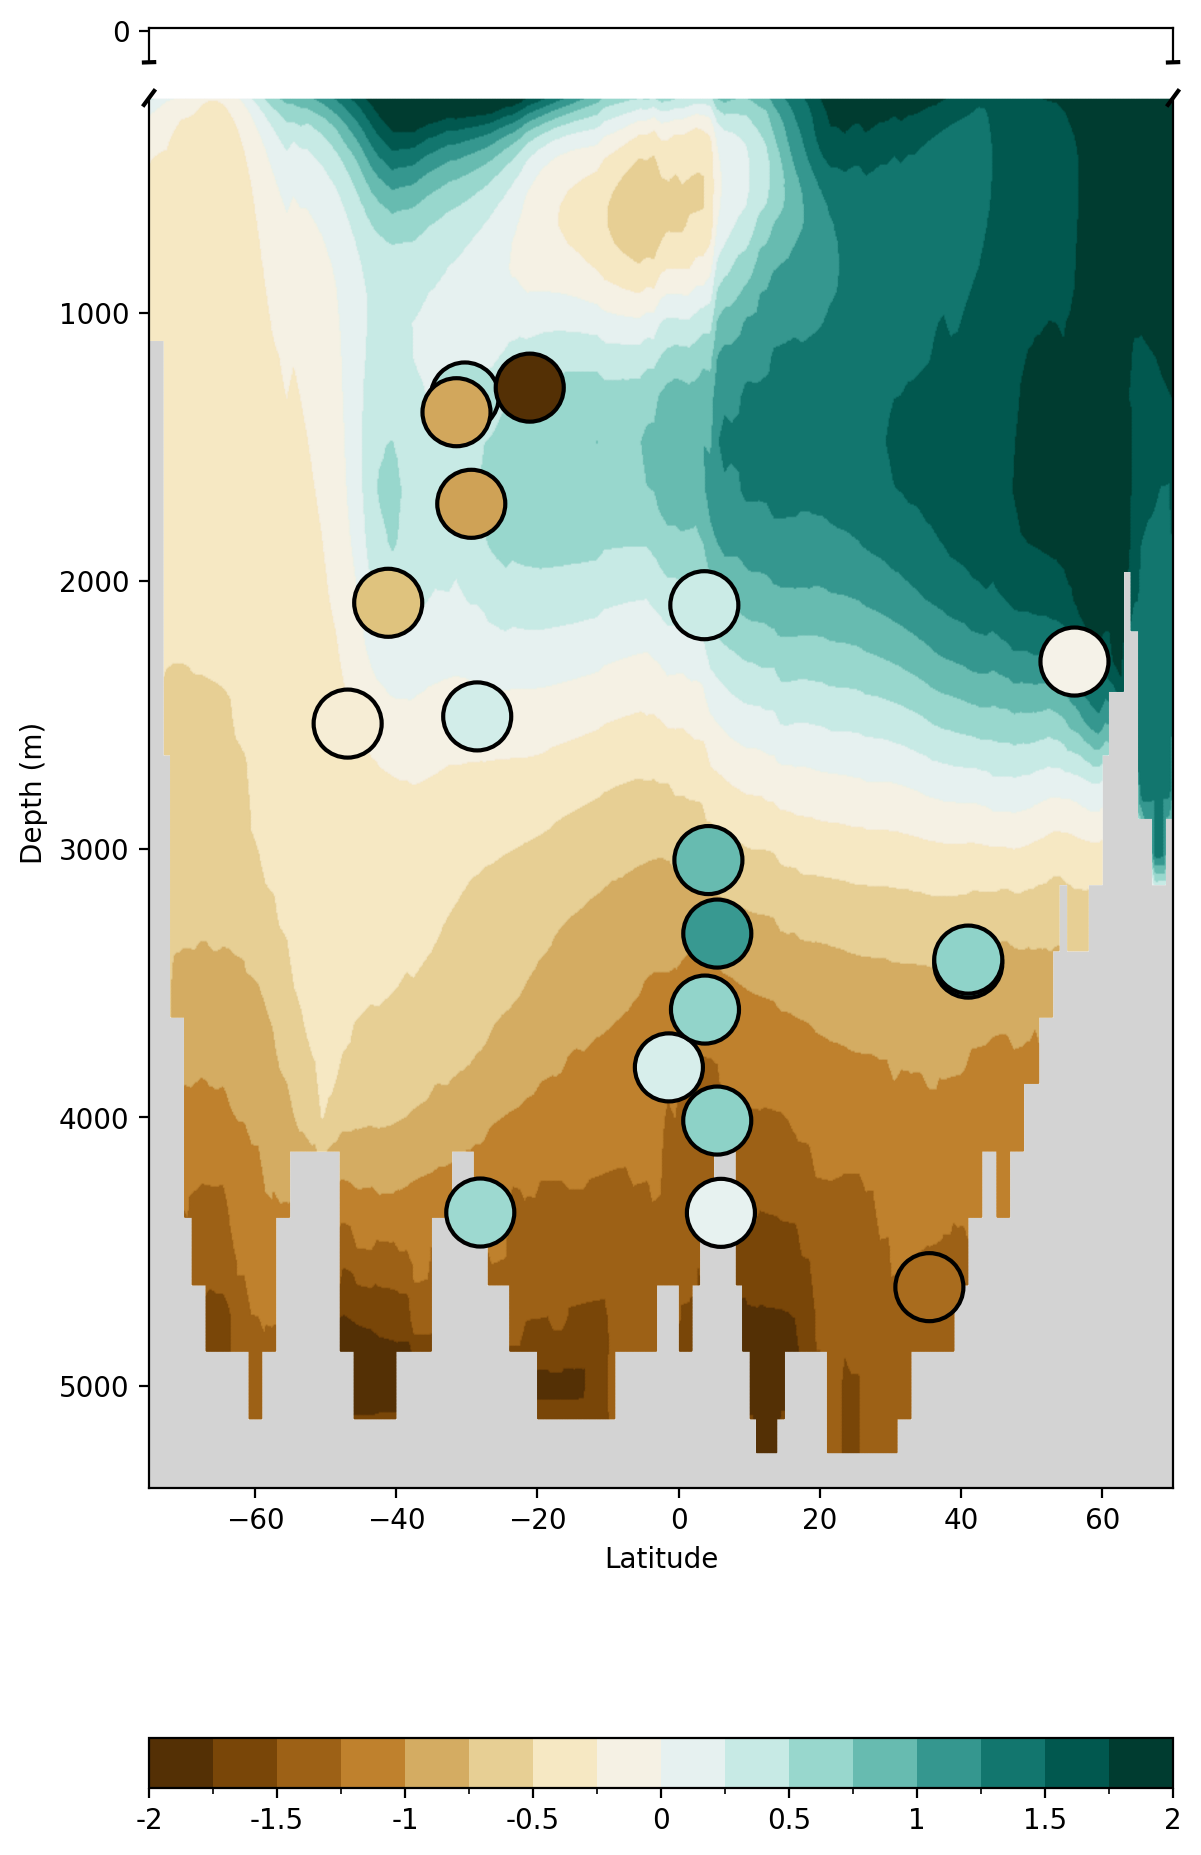

In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt

# Reset all matplotlib style params to defaults
mpl.rcParams.update(mpl.rcParamsDefault)
plt.rcdefaults()
mpl.rcParams.update({
    "font.size": 23,
    "axes.labelsize": 23,
    "xtick.labelsize": 23,
    "ytick.labelsize": 23,
})
plt.rcdefaults()

# Define color bins and colormap
color_bins_left = [-2, -1.75, -1.5, -1.25, -1, -0.75, -0.5, -0.25, 0, 0.25, 0.5, 0.75, 1, 1.25, 1.5, 1.75, 2]
num_colors_left = len(color_bins_left) - 1
colors_left = plt.cm.BrBG(np.linspace(0, 1, num_colors_left))
cmap_left = mcolors.ListedColormap(colors_left)
norm_left = mcolors.BoundaryNorm(boundaries=color_bins_left, ncolors=num_colors_left)

testplot, lat, depth = latdepthplot(
    cesm122_Plio_lat, cesm122_Plio_lon, cesm122_Plio_depth, cesm122_Plio_d13C,
    trimtop=True, normalise=False, top=200,
    mask=None, mask_lat=None, mask_lon=None,
)

mean = np.nanmean(testplot)
std = np.nanstd(testplot)
testplot = (testplot - mean) / std

fig = plt.figure(figsize=(8, 10), dpi=200)
fig.subplots_adjust(left=0.18, right=0.82, top=0.95, bottom=0.22)
inner_grid = fig.add_gridspec(2, 1, height_ratios=[1, 40], hspace=0.05)

ax1 = fig.add_subplot(inner_grid[0, 0])
ax2 = fig.add_subplot(inner_grid[1, 0], sharex=ax1)

shade_below_bathymetry(ax1, lat, depth, testplot)
pc1 = ax1.pcolormesh(lat, depth, testplot, cmap=cmap_left, norm=norm_left, shading='gouraud')
ax1.set_ylim(-1, 10)
ax1.set_xlim([-75, 70])
ax1.set_yticks([0])
ax1.tick_params(bottom=False, labelbottom=False)

shade_below_bathymetry(ax2, lat, depth, testplot)
pc2 = ax2.pcolormesh(lat, depth, testplot, cmap=cmap_left, norm=norm_left, shading='gouraud')
ax2.set_ylim(200, 5380)
ax2.set_xlim([-75, 70])
ax2.set_xlabel('Latitude')
ax2.set_ylabel('Depth (m)')
ax1.invert_yaxis()
ax2.invert_yaxis()

ax1.spines['bottom'].set_visible(False)
ax2.spines['top'].set_visible(False)

pliomip_points = PLIOMIP2_d13C_comparison_table["PLIOMIP2 d13C"]
points_mean = np.nanmean(pliomip_points)
points_std = np.nanstd(pliomip_points)
pliomip_points = (pliomip_points - points_mean) / points_std

ax2.scatter(
    PLIOMIP2_d13C_comparison_table["Latitude"],
    PLIOMIP2_d13C_comparison_table["Water depth (m)"],
    c=pliomip_points,
    cmap='BrBG',
    s=600,
    vmin=-2,
    vmax=2,
    marker='o',
    edgecolors='black',
    linewidths=1.5,
)

d = 0.005
kwargs = dict(transform=ax1.transAxes, color='k', clip_on=False)
ax1.plot((-d, +d), (-d, +d), **kwargs)
ax1.plot((1 - d, 1 + d), (-d, +d), **kwargs)

kwargs.update(transform=ax2.transAxes)
ax2.plot((-d, +d), (1 - d, 1 + d), **kwargs)
ax2.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)

cbar_ax = fig.add_axes([0.18, 0.07, 0.64, 0.025])
_cbar = plt.colorbar(pc2, cax=cbar_ax, orientation='horizontal', boundaries=color_bins_left, ticks=color_bins_left[::2])
_cbar.set_ticklabels([f"{t:g}" for t in color_bins_left[::2]])

plt.show()


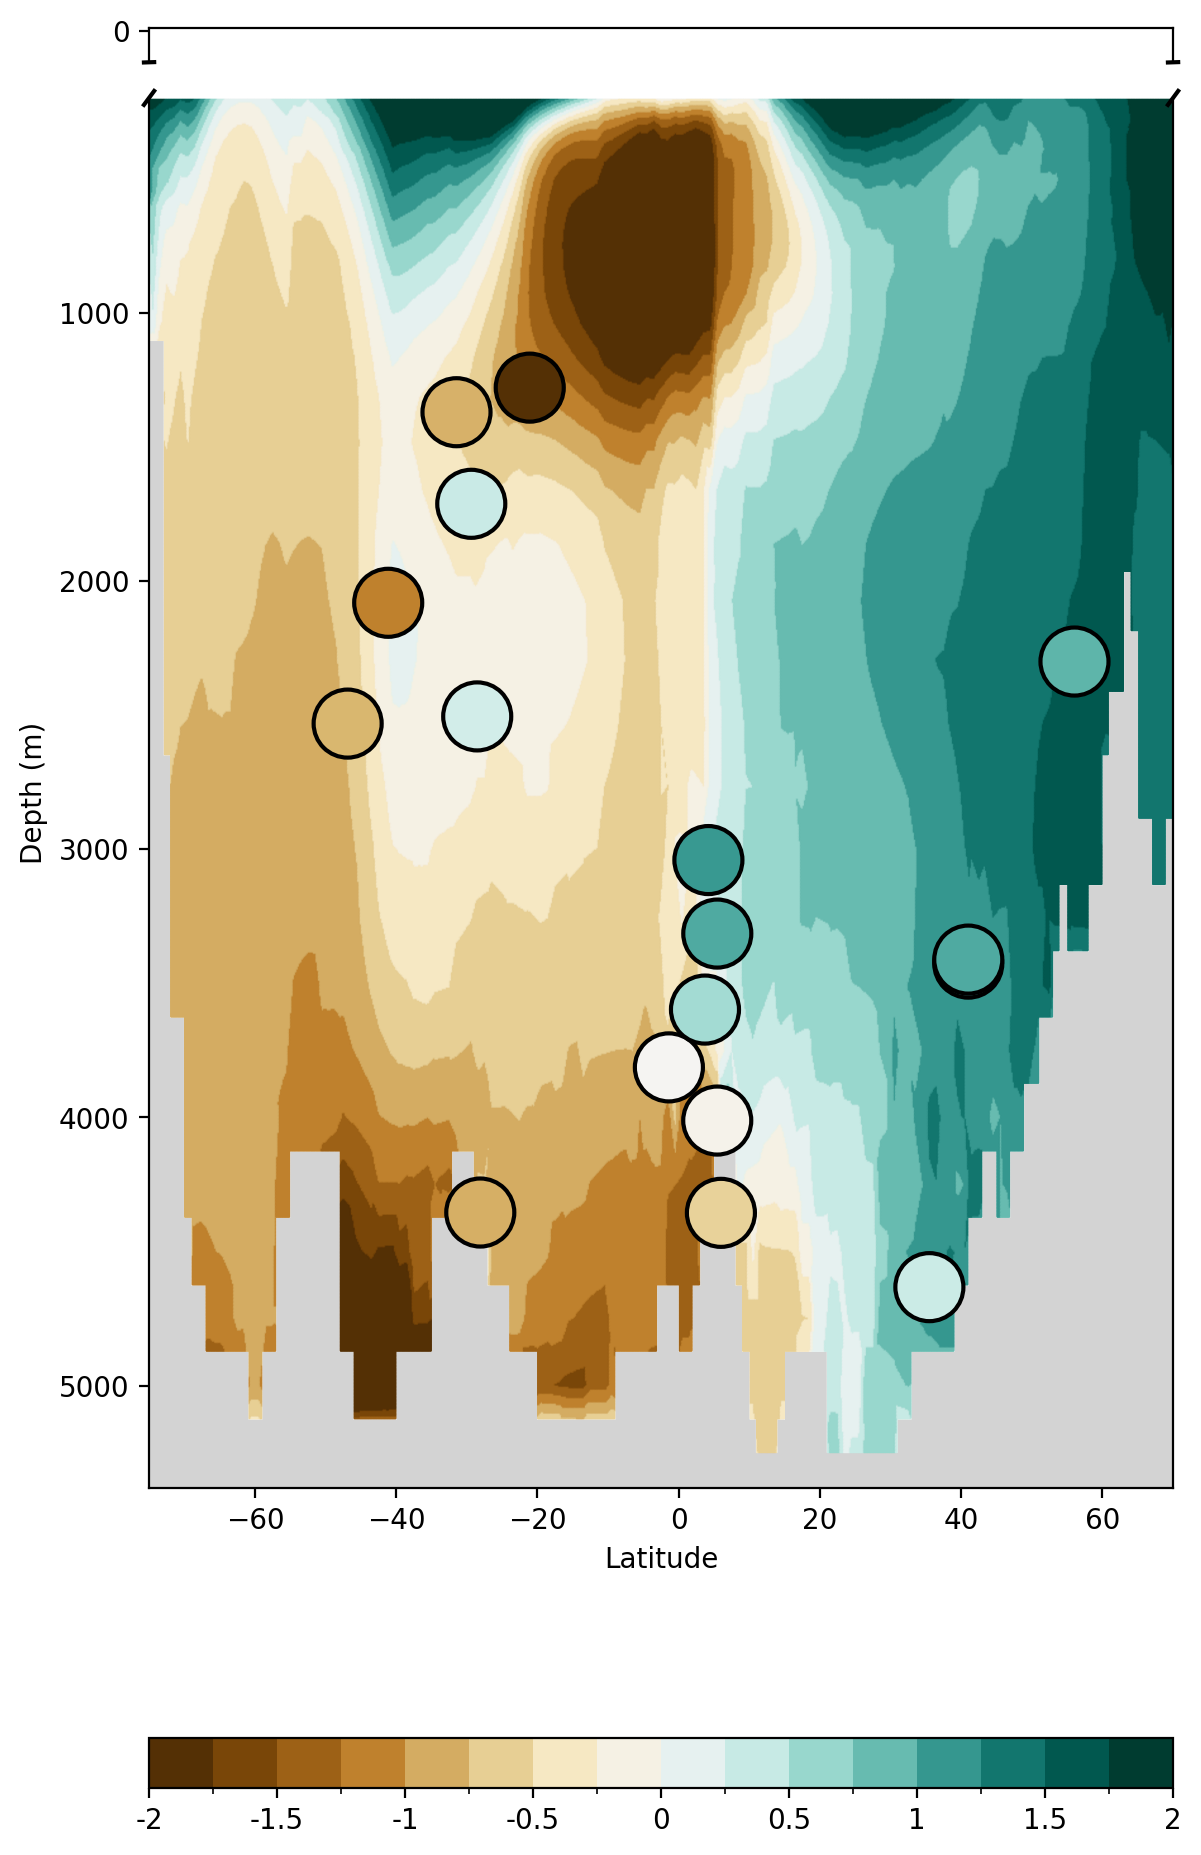

In [3]:
import matplotlib as mpl
import matplotlib.pyplot as plt

# Reset all matplotlib style params to defaults
mpl.rcParams.update(mpl.rcParamsDefault)
plt.rcdefaults()
mpl.rcParams.update({
    "font.size": 23,
    "axes.labelsize": 23,
    "xtick.labelsize": 23,
    "ytick.labelsize": 23,
})
plt.rcdefaults()

# Define color bins and colormap
color_bins_left = [-2, -1.75, -1.5, -1.25, -1, -0.75, -0.5, -0.25, 0, 0.25, 0.5, 0.75, 1, 1.25, 1.5, 1.75, 2]
num_colors_left = len(color_bins_left) - 1
colors_left = plt.cm.BrBG(np.linspace(0, 1, num_colors_left))
cmap_left = mcolors.ListedColormap(colors_left)
norm_left = mcolors.BoundaryNorm(boundaries=color_bins_left, ncolors=num_colors_left)

testplot, lat, depth = latdepthplot(
    cesm122_preind_lat, cesm122_preind_lon, cesm122_preind_depth, cesm122_preind_d13C,
    trimtop=True, normalise=False, top=200,
    mask=None, mask_lat=None, mask_lon=None,
)

mean = np.nanmean(testplot)
std = np.nanstd(testplot)
testplot = (testplot - mean) / std

fig = plt.figure(figsize=(8, 10), dpi=200)
fig.subplots_adjust(left=0.18, right=0.82, top=0.95, bottom=0.22)
inner_grid = fig.add_gridspec(2, 1, height_ratios=[1, 40], hspace=0.05)

ax1 = fig.add_subplot(inner_grid[0, 0])
ax2 = fig.add_subplot(inner_grid[1, 0], sharex=ax1)

shade_below_bathymetry(ax1, lat, depth, testplot)
pc1 = ax1.pcolormesh(lat, depth, testplot, cmap=cmap_left, norm=norm_left, shading='gouraud')
ax1.set_ylim(-1, 10)
ax1.set_xlim([-75, 70])
ax1.set_yticks([0])
ax1.tick_params(bottom=False, labelbottom=False)

shade_below_bathymetry(ax2, lat, depth, testplot)
pc2 = ax2.pcolormesh(lat, depth, testplot, cmap=cmap_left, norm=norm_left, shading='gouraud')
ax2.set_ylim(200, 5380)
ax2.set_xlim([-75, 70])
ax2.set_xlabel('Latitude')
ax2.set_ylabel('Depth (m)')
ax1.invert_yaxis()
ax2.invert_yaxis()

ax1.spines['bottom'].set_visible(False)
ax2.spines['top'].set_visible(False)

oc3_points = PLIOMIP2_d13C_comparison_table["OC3 d13C"]
points_mean = np.nanmean(oc3_points)
points_std = np.nanstd(oc3_points)
oc3_points = (oc3_points - points_mean) / points_std

ax2.scatter(
    PLIOMIP2_d13C_comparison_table["Latitude"],
    PLIOMIP2_d13C_comparison_table["Water depth (m)"],
    c=oc3_points,
    cmap='BrBG',
    s=600,
    vmin=-2,
    vmax=2,
    marker='o',
    edgecolors='black',
    linewidths=1.5,
)

d = 0.005
kwargs = dict(transform=ax1.transAxes, color='k', clip_on=False)
ax1.plot((-d, +d), (-d, +d), **kwargs)
ax1.plot((1 - d, 1 + d), (-d, +d), **kwargs)

kwargs.update(transform=ax2.transAxes)
ax2.plot((-d, +d), (1 - d, 1 + d), **kwargs)
ax2.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)

cbar_ax = fig.add_axes([0.18, 0.07, 0.64, 0.025])
_cbar = plt.colorbar(pc2, cax=cbar_ax, orientation='horizontal', boundaries=color_bins_left, ticks=color_bins_left[::2])
_cbar.set_ticklabels([f"{t:g}" for t in color_bins_left[::2]])

plt.show()


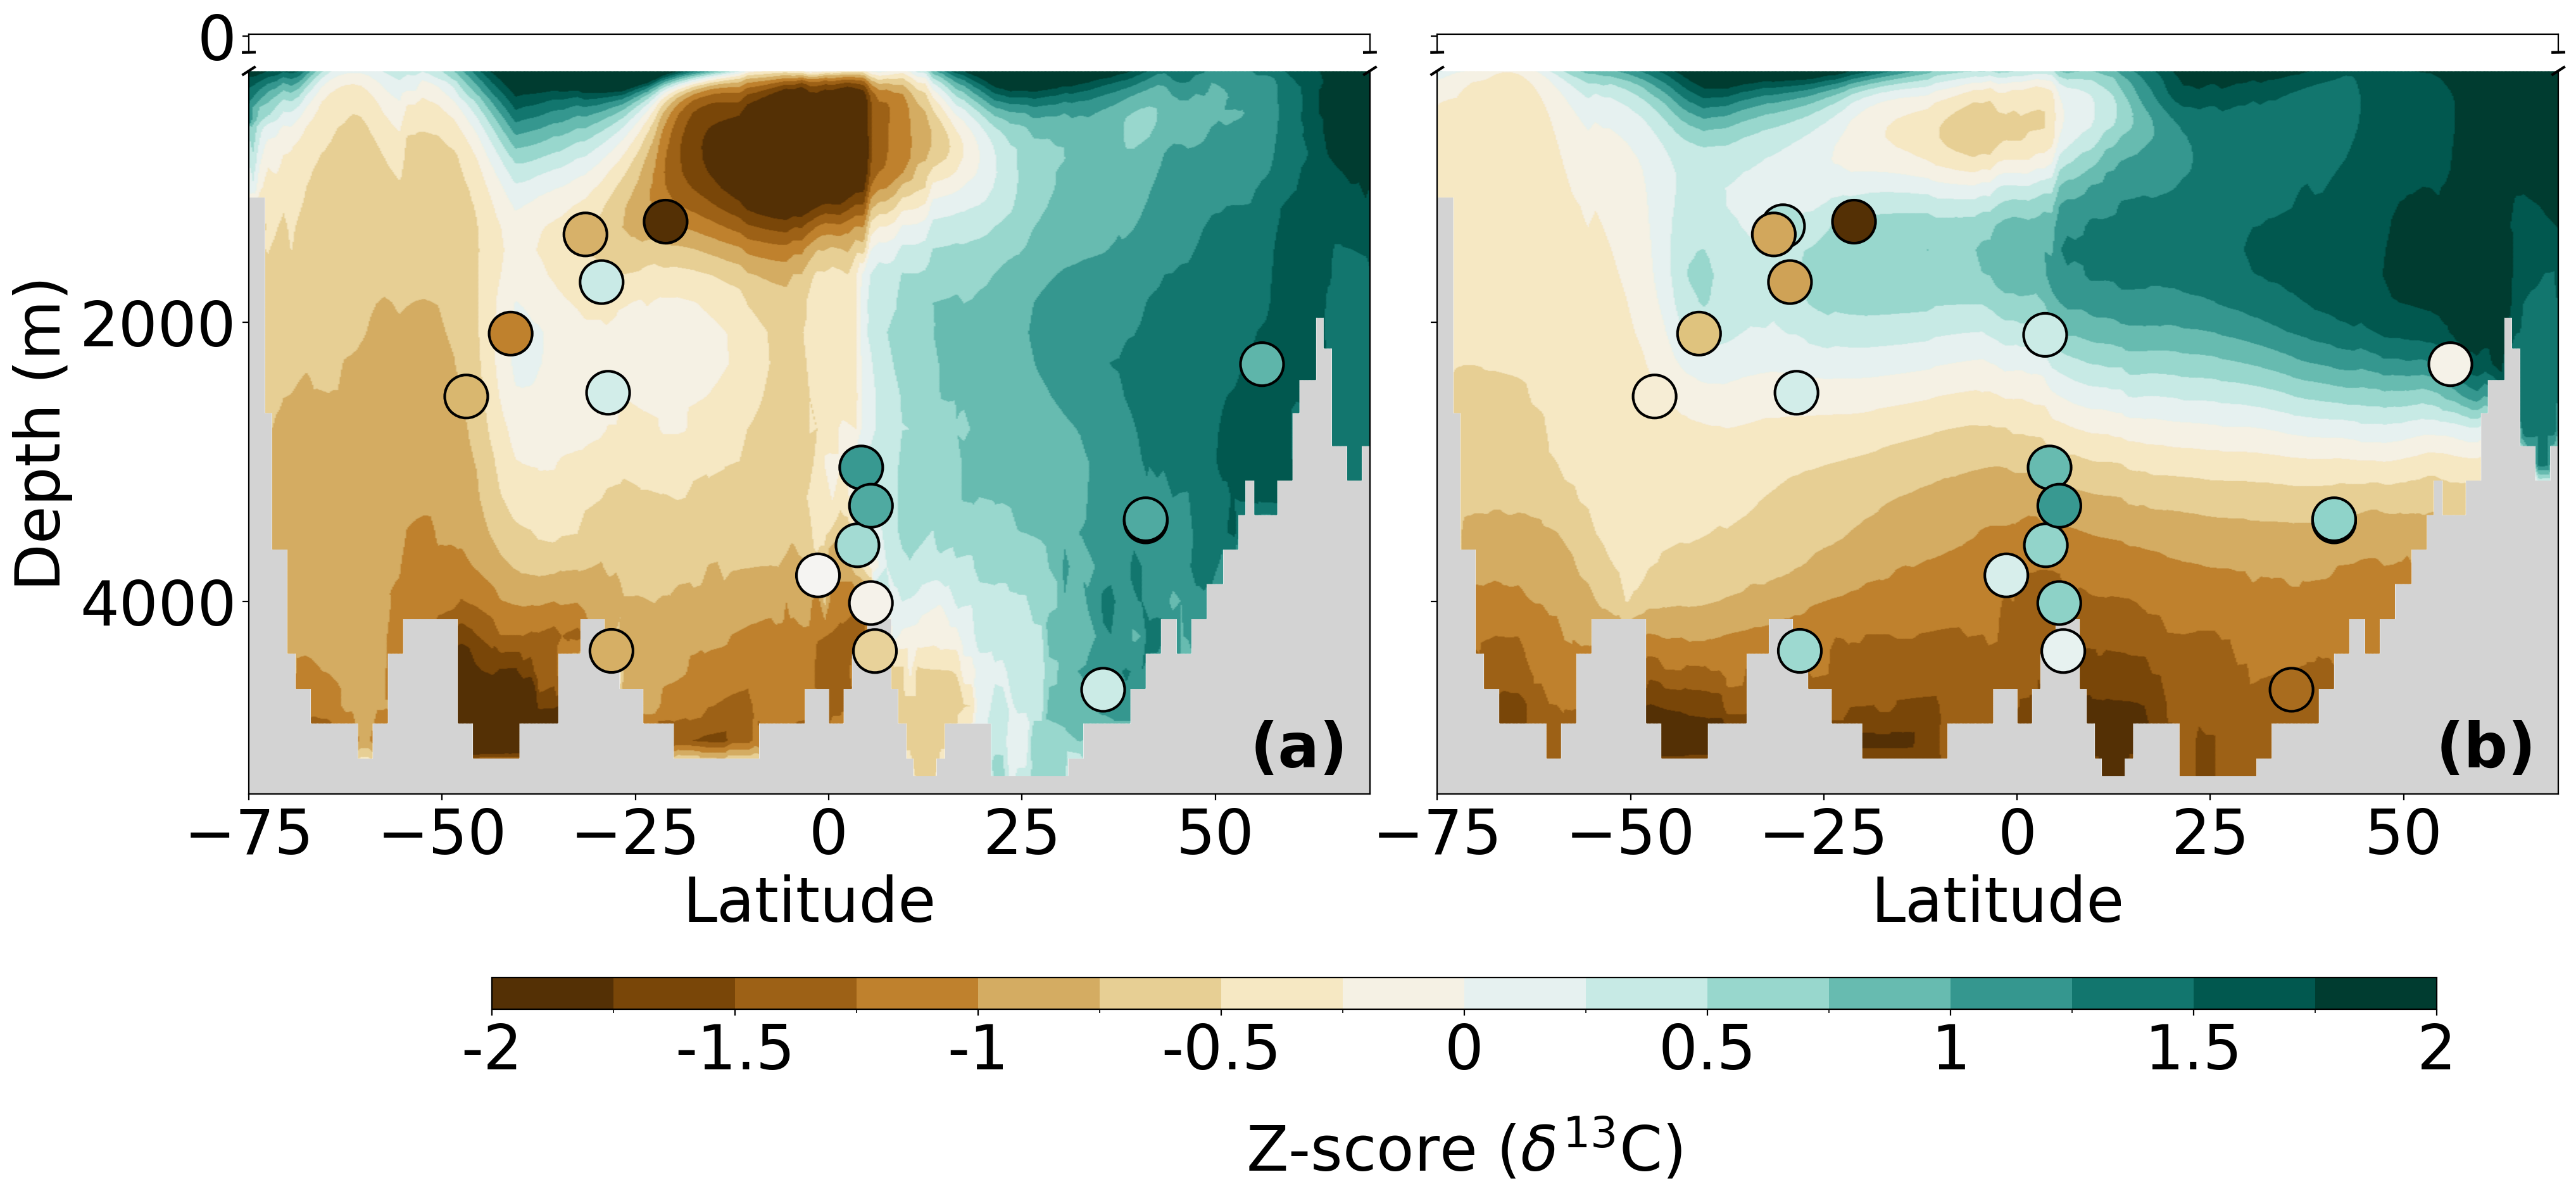

In [4]:
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update(mpl.rcParamsDefault)
plt.rcdefaults()
mpl.rcParams.update({
    "font.size": 35,
    "axes.labelsize": 35,
    "xtick.labelsize": 35,
    "ytick.labelsize": 35,
})

color_bins = [-2, -1.75, -1.5, -1.25, -1, -0.75, -0.5, -0.25, 0, 0.25, 0.5, 0.75, 1, 1.25, 1.5, 1.75, 2]
num_colors = len(color_bins) - 1
colors = plt.cm.BrBG(np.linspace(0, 1, num_colors))
cmap = mcolors.ListedColormap(colors)
norm = mcolors.BoundaryNorm(boundaries=color_bins, ncolors=num_colors)

panels = [
    {
        "lat": cesm122_preind_lat,
        "lon": cesm122_preind_lon,
        "depth_data": cesm122_preind_depth,
        "field": cesm122_preind_d13C,
        "scatter_col": "OC3 d13C",
        "label": "(a)",
    },
    {
        "lat": cesm122_Plio_lat,
        "lon": cesm122_Plio_lon,
        "depth_data": cesm122_Plio_depth,
        "field": cesm122_Plio_d13C,
        "scatter_col": "PLIOMIP2 d13C",
        "label": "(b)",
    },
]

fig = plt.figure(figsize=(24, 10), dpi=200)
outer_grid = fig.add_gridspec(
    1, 2, wspace=0.06,
    left=0.10, right=0.86, top=0.94, bottom=0.34,
)

pc_for_cbar = None

for col, panel in enumerate(panels):
    testplot, lat, depth = latdepthplot(
        panel["lat"], panel["lon"], panel["depth_data"], panel["field"],
        trimtop=True, normalise=False, top=200,
        mask=None, mask_lat=None, mask_lon=None,
    )

    plot_mean = np.nanmean(testplot)
    plot_std = np.nanstd(testplot)
    testplot = (testplot - plot_mean) / plot_std

    inner_grid = outer_grid[0, col].subgridspec(2, 1, height_ratios=[1, 40], hspace=0.05)
    ax1 = fig.add_subplot(inner_grid[0, 0])
    ax2 = fig.add_subplot(inner_grid[1, 0], sharex=ax1)

    shade_below_bathymetry(ax1, lat, depth, testplot)
    ax1.pcolormesh(lat, depth, testplot, cmap=cmap, norm=norm, shading='gouraud')
    ax1.set_ylim(-1, 10)
    ax1.set_xlim([-75, 70])
    ax1.set_yticks([0])
    ax1.tick_params(bottom=False, labelbottom=False)
    if col == 1:
        ax1.tick_params(labelleft=False)

    shade_below_bathymetry(ax2, lat, depth, testplot)
    pc_for_cbar = ax2.pcolormesh(lat, depth, testplot, cmap=cmap, norm=norm, shading='gouraud')
    ax2.set_ylim(200, 5380)
    ax2.set_xlim([-75, 70])
    ax2.set_xlabel('Latitude')
    if col == 0:
        ax2.set_ylabel('Depth (m)')
    else:
        ax2.tick_params(labelleft=False)

    ax1.invert_yaxis()
    ax2.invert_yaxis()

    ax1.spines['bottom'].set_visible(False)
    ax2.spines['top'].set_visible(False)

    scatter_values = PLIOMIP2_d13C_comparison_table[panel["scatter_col"]]
    scatter_mean = np.nanmean(scatter_values)
    scatter_std = np.nanstd(scatter_values)
    scatter_values = (scatter_values - scatter_mean) / scatter_std

    ax2.scatter(
        PLIOMIP2_d13C_comparison_table["Latitude"],
        PLIOMIP2_d13C_comparison_table["Water depth (m)"],
        c=scatter_values,
        cmap='BrBG',
        s=600,
        vmin=-2,
        vmax=2,
        marker='o',
        edgecolors='black',
        linewidths=1.5,
    )

    d = 0.005
    kwargs = dict(transform=ax1.transAxes, color='k', clip_on=False)
    ax1.plot((-d, +d), (-d, +d), **kwargs)
    ax1.plot((1 - d, 1 + d), (-d, +d), **kwargs)
    kwargs.update(transform=ax2.transAxes)
    ax2.plot((-d, +d), (1 - d, 1 + d), **kwargs)
    ax2.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)

    ax2.text(
        0.98, 0.02, panel["label"],
        transform=ax2.transAxes,
        ha="right", va="bottom",
        fontsize=35, fontweight="bold",
        zorder=20,
    )

cbar_ax = fig.add_axes([0.18, 0.17, 0.64, 0.025])
cbar = plt.colorbar(pc_for_cbar, cax=cbar_ax, orientation='horizontal', boundaries=color_bins, ticks=color_bins[::2])
cbar.set_ticklabels([f"{t:g}" for t in color_bins[::2]])
cbar.set_label(r'Z-score ($\delta^{13}\mathrm{C}$)', fontsize=35, labelpad=20)

fig.savefig(FIG_DIR / "d13C_with_points.png", dpi=300, bbox_inches="tight")
plt.show()
